In [1]:
# quiver plot
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature  

In [2]:
ws = xr.open_dataset("vs_2021.nc")
ws.info()

xarray.Dataset {
dimensions:
	day = 365 ;
	lat = 585 ;
	lon = 1386 ;
	crs = 1 ;

variables:
	float64 wind_speed(day, lat, lon) ;
		wind_speed:units = m/s ;
		wind_speed:description = Daily Mean Wind Speed (10m) ;
		wind_speed:long_name = vs ;
		wind_speed:standard_name = vs ;
		wind_speed:dimensions = lon lat time ;
		wind_speed:grid_mapping = crs ;
		wind_speed:coordinate_system = WGS84,EPSG:4326 ;
	float64 lon(lon) ;
		lon:units = degrees_east ;
		lon:description = longitude ;
		lon:long_name = longitude ;
		lon:standard_name = longitude ;
		lon:axis = X ;
	float64 lat(lat) ;
		lat:units = degrees_north ;
		lat:description = latitude ;
		lat:long_name = latitude ;
		lat:standard_name = latitude ;
		lat:axis = Y ;
	datetime64[ns] day(day) ;
		day:description = days since 1900-01-01 ;
		day:long_name = time ;
		day:standard_name = time ;
	uint16 crs(crs) ;
		crs:grid_mapping_name = latitude_longitude ;
		crs:longitude_of_prime_meridian = 0.0 ;
		crs:semi_major_axis = 6378137.0 ;
		crs:

In [3]:
wd = xr.open_dataset("th_2021.nc")
wd.info()

xarray.Dataset {
dimensions:
	day = 365 ;
	lat = 585 ;
	lon = 1386 ;
	crs = 1 ;

variables:
	float64 wind_from_direction(day, lat, lon) ;
		wind_from_direction:units = Degrees Clockwise from north ;
		wind_from_direction:description = Daily mean wind direction (10m) ;
		wind_from_direction:long_name = th ;
		wind_from_direction:standard_name = th ;
		wind_from_direction:dimensions = lon lat time ;
		wind_from_direction:grid_mapping = crs ;
		wind_from_direction:coordinate_system = WGS84,EPSG:4326 ;
	float64 lon(lon) ;
		lon:units = degrees_east ;
		lon:description = longitude ;
		lon:long_name = longitude ;
		lon:standard_name = longitude ;
		lon:axis = X ;
	float64 lat(lat) ;
		lat:units = degrees_north ;
		lat:description = latitude ;
		lat:long_name = latitude ;
		lat:standard_name = latitude ;
		lat:axis = Y ;
	datetime64[ns] day(day) ;
		day:description = days since 1900-01-01 ;
		day:long_name = time ;
		day:standard_name = time ;
	uint16 crs(crs) ;
		crs:grid_mapping_name = lati

In [4]:

# Names of all data variables
print(list(ws.data_vars))
print(list(wd.data_vars))
print(ws.coords)
print(wd.coords)

['wind_speed']
['wind_from_direction']
Coordinates:
  * day      (day) datetime64[ns] 3kB 2021-01-01 2021-01-02 ... 2021-12-31
  * lat      (lat) float64 5kB 49.4 49.36 49.32 49.28 ... 25.15 25.11 25.07
  * lon      (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.14 -67.1 -67.06
  * crs      (crs) uint16 2B 3
Coordinates:
  * day      (day) datetime64[ns] 3kB 2021-01-01 2021-01-02 ... 2021-12-31
  * lat      (lat) float64 5kB 49.4 49.36 49.32 49.28 ... 25.15 25.11 25.07
  * lon      (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.14 -67.1 -67.06
  * crs      (crs) uint16 2B 3


In [5]:
jasws = ws.sel(day=slice("2021-07-01", "2021-09-30"))
jaswd = wd.sel(day=slice("2021-07-01", "2021-09-30"))

In [6]:
print(jasws)
print(jasws["wind_speed"])
print(jasws["wind_speed"].dims)
print(jasws["wind_speed"].shape)
print(jasws["wind_speed"].attrs)

<xarray.Dataset> Size: 597MB
Dimensions:     (day: 92, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day         (day) datetime64[ns] 736B 2021-07-01 2021-07-02 ... 2021-09-30
  * lat         (lat) float64 5kB 49.4 49.36 49.32 49.28 ... 25.15 25.11 25.07
  * lon         (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.14 -67.1 -67.06
  * crs         (crs) uint16 2B 3
Data variables:
    wind_speed  (day, lat, lon) float64 597MB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       03 March 2022
    note1:                      The projection information for this file is: ...
    note2:                      Citation: Abatzoglou, J.T., 2013, De

In [7]:
print(jaswd)
print(jaswd["wind_from_direction"])
print(jaswd["wind_from_direction"].dims)
print(jaswd["wind_from_direction"].shape)
print(jaswd["wind_from_direction"].attrs)

<xarray.Dataset> Size: 597MB
Dimensions:              (day: 92, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day                  (day) datetime64[ns] 736B 2021-07-01 ... 2021-09-30
  * lat                  (lat) float64 5kB 49.4 49.36 49.32 ... 25.11 25.07
  * lon                  (lon) float64 11kB -124.8 -124.7 ... -67.1 -67.06
  * crs                  (crs) uint16 2B 3
Data variables:
    wind_from_direction  (day, lat, lon) float64 597MB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       03 March 2022
    note1:                      The projection information for this file is: ...
    note2:                      Citation: Abatzoglo

In [8]:
## Confirm grids match exactly before merging
xr.testing.assert_equal(jasws["lat"], jaswd["lat"])
xr.testing.assert_equal(jasws["lon"], jaswd["lon"])
xr.testing.assert_equal(jasws["day"], jaswd["day"])

In [9]:
#merge both data slices into one
dw = xr.merge([jasws["wind_speed"], jaswd["wind_from_direction"]])

In [10]:
# check min,max values of wind speed and wind direction
print(dw["wind_speed"].min().item())
print(dw["wind_speed"].max().item())
print(dw["wind_from_direction"].min().item())
print(dw["wind_from_direction"].max().item())

0.30000000000000004
16.3
0.0
360.0


In [11]:
ws = dw["wind_speed"].where((dw["wind_speed"] >= 0) & (dw["wind_speed"] < 60))
print(ws)
wd = (dw["wind_from_direction"] % 360).where(ws.notnull())
print(wd)
wd = wd.where(ws > 0)   

<xarray.DataArray 'wind_speed' (day: 92, lat: 585, lon: 1386)> Size: 597MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        

In [12]:
rad = np.deg2rad(wd)
u = -ws * np.sin(rad)
v = -ws * np.cos(rad)
u = u.fillna(0).where(ws.notnull())
v = v.fillna(0).where(ws.notnull())

In [13]:
u_2w = u.coarsen(day=14, boundary="trim").mean()
v_2w = v.coarsen(day=14, boundary="trim").mean()

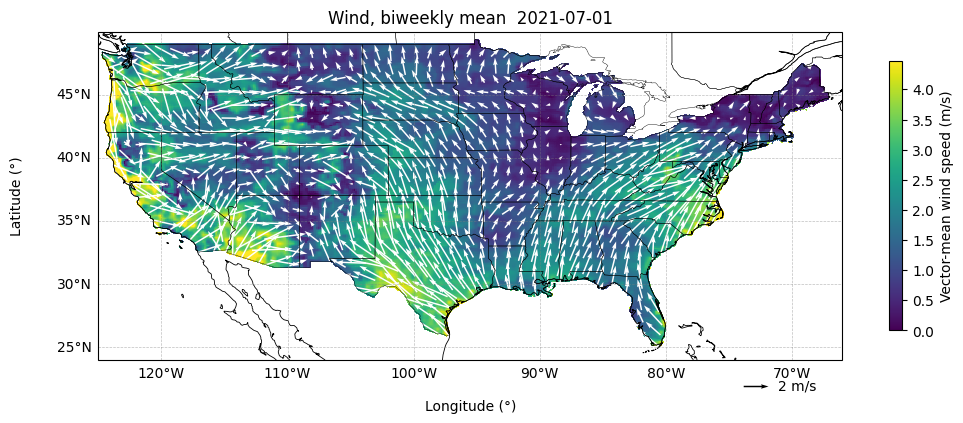

In [35]:


blk = 0                                   # which 2-week block (0 = Jul 1-14)
ub = u_2w.isel(day=blk).compute()
vb = v_2w.isel(day=blk).compute()
speed = np.hypot(ub, vb)                  # vector-mean speed, for the background

vmin = 0
vmax = float(speed.quantile(0.99))    # or float(speed_all.max())

step = 25                                 # arrow spacing in grid cells (~1 degree)
us = ub.isel(lat=slice(None, None, step), lon=slice(None, None, step))
vs = vb.isel(lat=slice(None, None, step), lon=slice(None, None, step))

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())

 # Background: speed
pm = ax.pcolormesh(ub["lon"], ub["lat"], speed.values,cmap="viridis",vmin=vmin,vmax=vmax)

plt.colorbar(pm, ax=ax, shrink=0.7, label="Vector-mean wind speed (m/s)")

q = ax.quiver(us["lon"], us["lat"], us.values, vs.values,
              transform=ccrs.PlateCarree(),
              color="white", scale=60, width=0.002, pivot="mid")
              

ax.quiverkey(q, 0.9, -0.08, 2, "2 m/s", labelpos="E", coordinates="axes", color="k")

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.STATES, linewidth=0.3)
# Add longitude and latitude labels
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color="gray",
    alpha=0.5,
    linestyle="--"
)

gl.top_labels = False
gl.right_labels = False

gl.xlabel_style = {"size": 10}
gl.ylabel_style = {"size": 10}

# Axis labels
ax.text(0.5, -0.12, "Longitude (°)", transform=ax.transAxes, ha="center", va="top")
ax.text(-0.10, 0.5, "Latitude (°)", transform=ax.transAxes, ha="right", va="center", rotation="vertical")
first_day = str(u["day"].values[blk * 14])[:10]
ax.set_title(f"Wind, biweekly mean  {first_day }")          
fig.savefig(f"Wind_biweekly_mean.png", dpi=200)
plt.show()

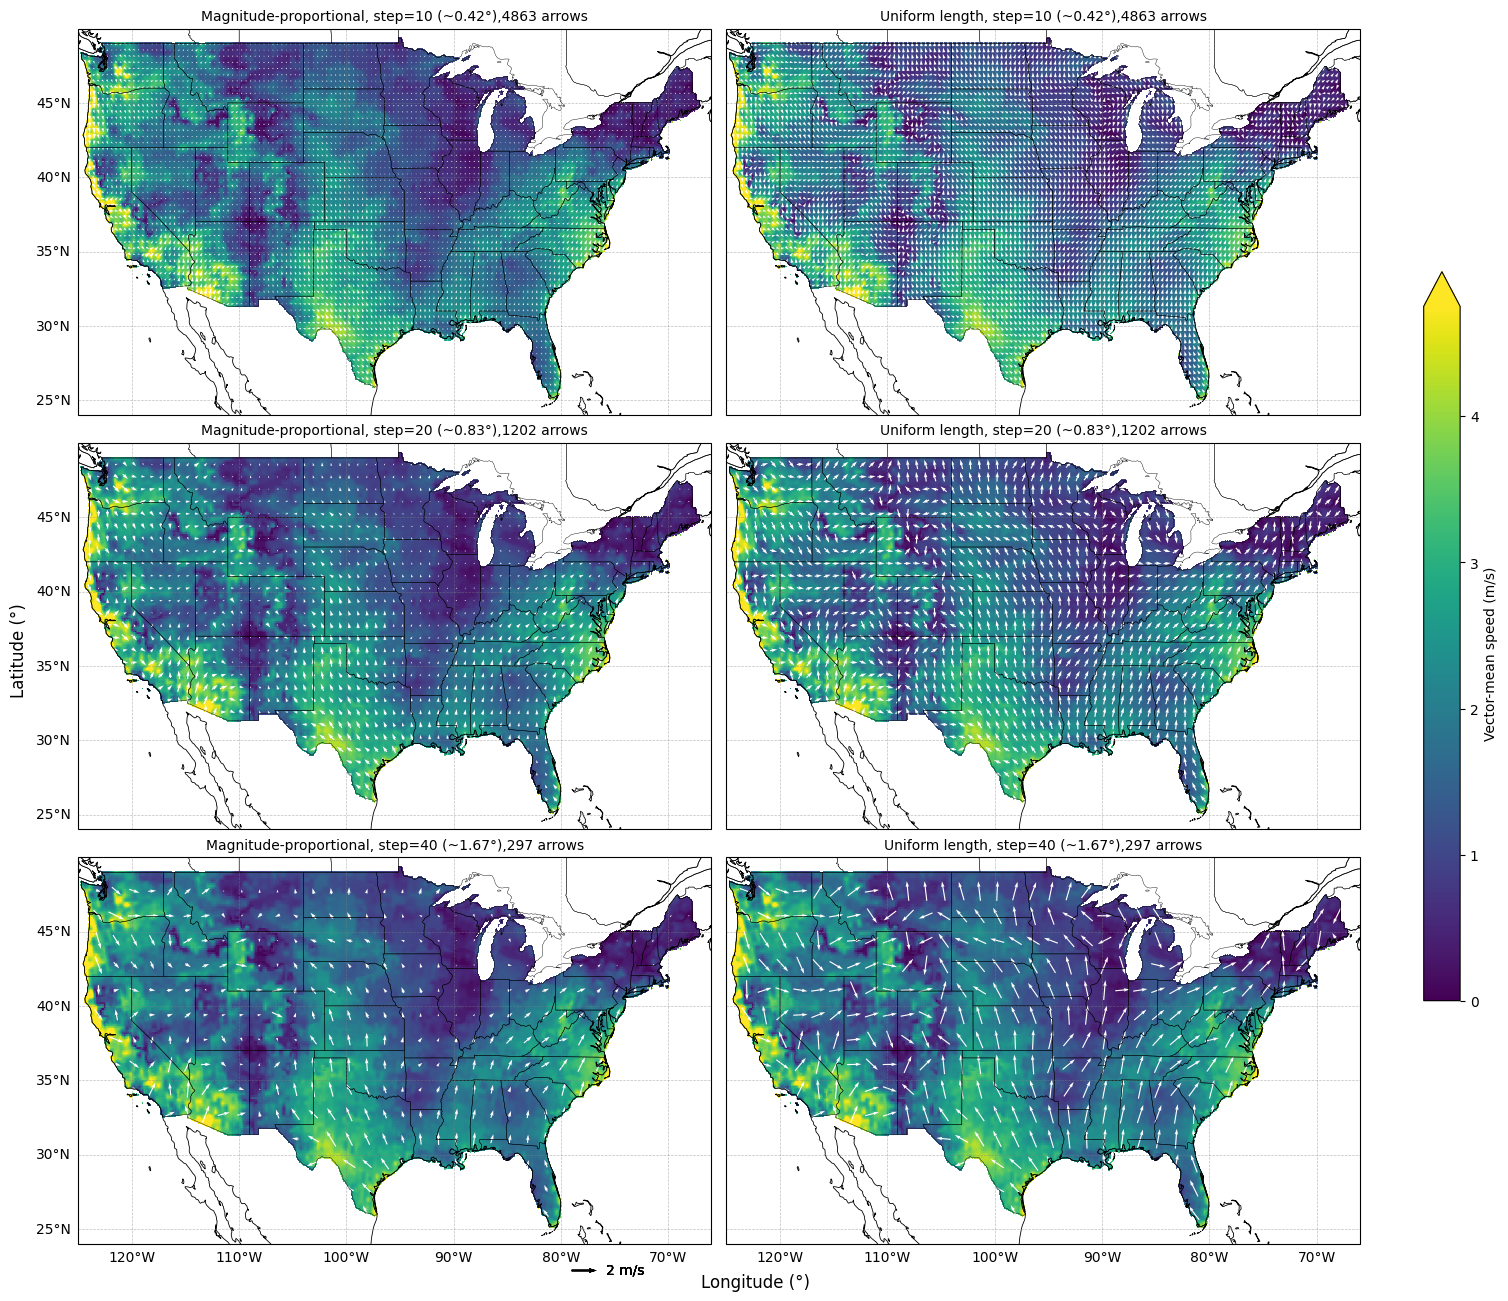

In [33]:
#Grid sampling experiment
import numpy as np
import matplotlib.pyplot as plt

blk = 0
ub = u_2w.isel(day=blk).compute()
vb = v_2w.isel(day=blk).compute()

speed = np.hypot(ub, vb)

# one global color range (same as your animation frames)
vmin, vmax = 0, float(np.hypot(u_2w, v_2w).quantile(0.99))

dlat = abs(float(ub["lat"][1] - ub["lat"][0]))     # grid spacing in degrees (~0.042)
steps = [10, 20, 40]                                # sampling experiments
method = "stride"                                   # "stride" or "coarsen"

def sample(da, step, method):
    if method == "stride":      # pick every step-th cell
        return da.isel(lat=slice(None, None, step), lon=slice(None, None, step))
    # average u/v over step x step cells (safe, since these are components)
    return da.coarsen(lat=step, lon=step, boundary="trim").mean()


fig, axes = plt.subplots(len(steps), 2, figsize=(15, 4.3 * len(steps)),
                         sharex=True, sharey=True, constrained_layout=True,subplot_kw={"projection": ccrs.PlateCarree()})

for i, step in enumerate(steps):
    us, vs = sample(ub, step, method), sample(vb, step, method)
    mag = np.hypot(us, vs)
    spacing = step * dlat                           # distance between arrows, in degrees

    for j, mode in enumerate(["Magnitude-proportional", "Uniform length"]):
        ax = axes[i, j]
         # Background: speed

        ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
        pm = ax.pcolormesh(ub["lon"], ub["lat"], speed.values,cmap="viridis",vmin=vmin,vmax=vmax)

        if j == 0:
            U, V = us.values, vs.values
            scale = vmax / spacing                  # vmax m/s -> arrow as long as the spacing
        else:
            U, V = (us / mag).values, (vs / mag).values
            scale = 1 / (0.8 * spacing)             # every arrow = 80% of the spacing

        ax.quiver(us["lon"], us["lat"], U, V,
                  angles="xy", scale_units="xy", scale=scale,transform=ccrs.PlateCarree(),
                  color="white", width=0.0018, pivot="mid")         

        ax.quiverkey(q, 0.6, -0.16, 2, "2 m/s", labelpos="E", coordinates="axes", color="k")
        
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.STATES, linewidth=0.3)

        # Add longitude and latitude labels
        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0.5,
            color="gray",
            alpha=0.5,
            linestyle="--"
        )

        gl.top_labels = False
        gl.right_labels = False
        gl.left_labels = (j == 0)            # only the first column
        gl.bottom_labels = (i == len(steps) - 1)  # only the last row

        gl.xlabel_style = {"size": 10}
        gl.ylabel_style = {"size": 10}

        ax.set_aspect("auto")
        ax.set_title(f"{mode}, step={step} (~{spacing:.2f}°),"
                     f"{us.size - int(np.isnan(us.values).sum())} arrows", fontsize=10)
        
fig.supxlabel("Longitude (°)")
fig.supylabel("Latitude (°)")
fig.colorbar(pm, ax=axes, shrink=0.6, label="Vector-mean speed (m/s)", extend="max")
fig.savefig(f"sampling_comparison_{method}_blk{blk:02d}.png", dpi=200)
plt.show()

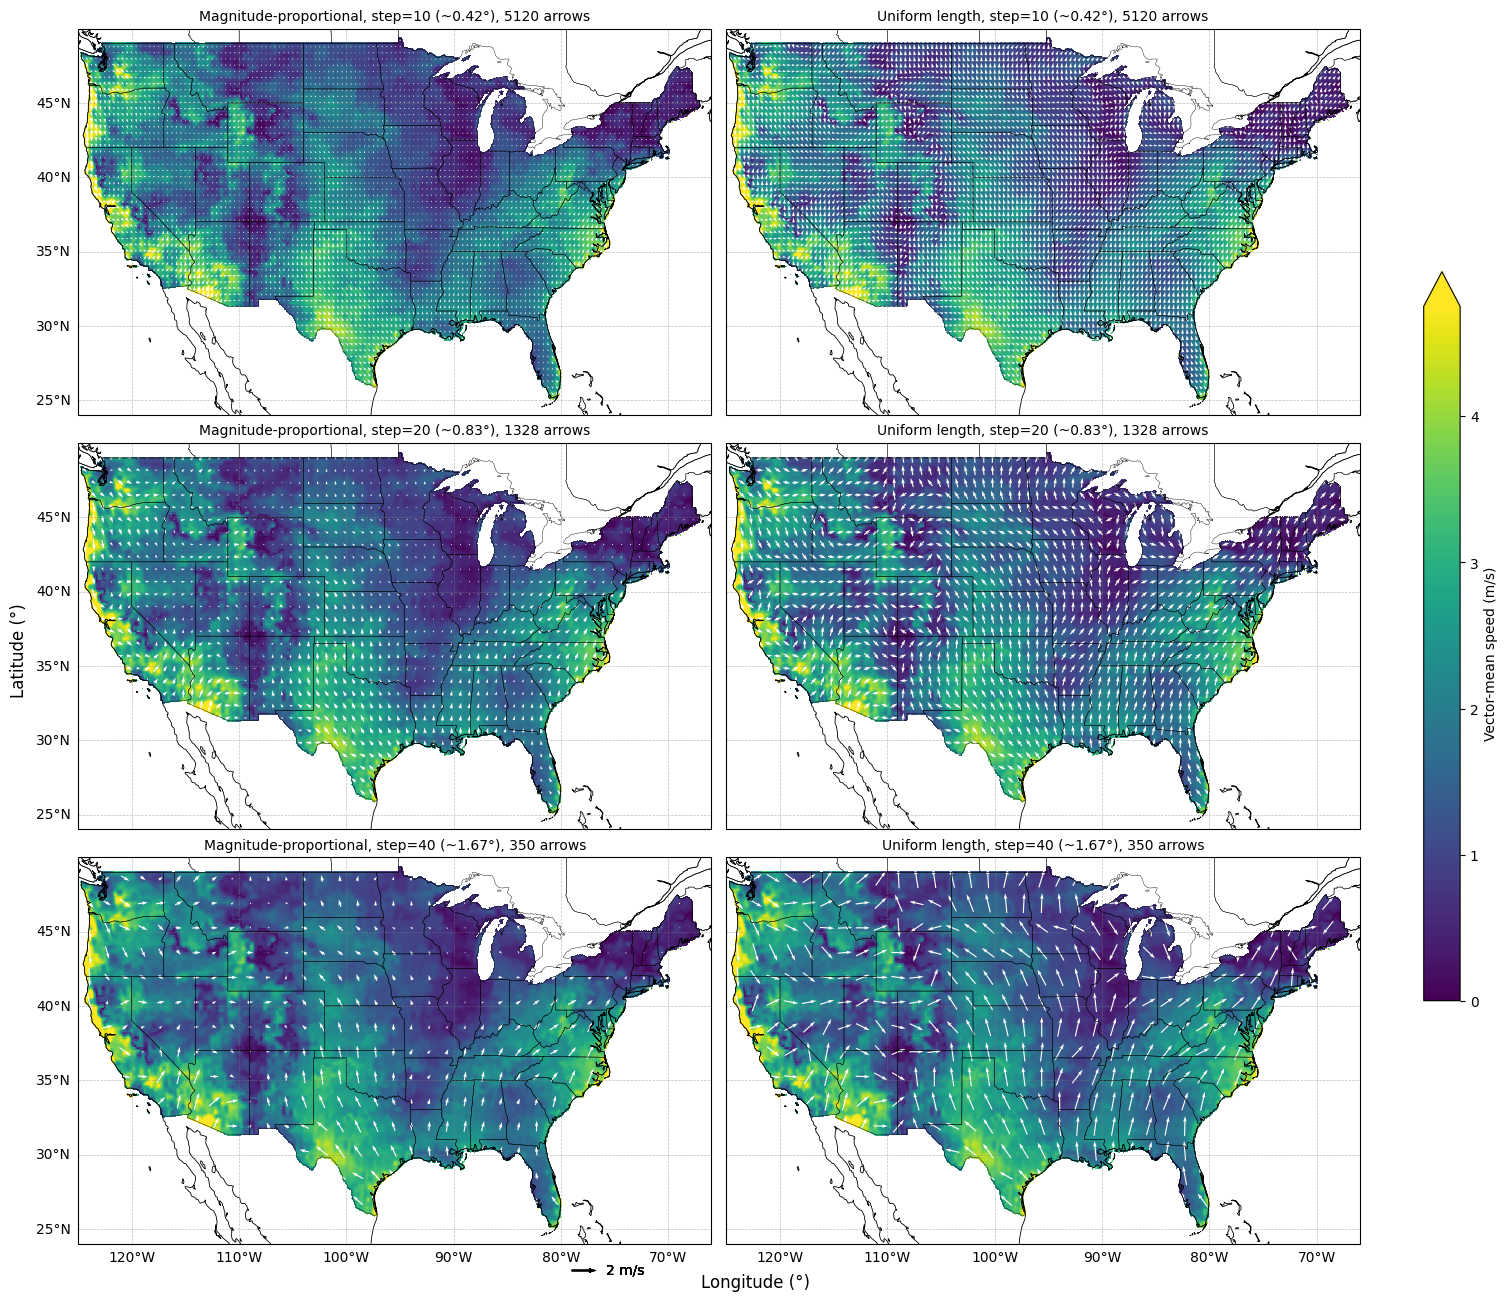

In [34]:
#Grid sampling experiment
import numpy as np
import matplotlib.pyplot as plt

blk = 0
ub = u_2w.isel(day=blk).compute()
vb = v_2w.isel(day=blk).compute()

speed = np.hypot(ub, vb)

# one global color range (same as your animation frames)
vmin, vmax = 0, float(np.hypot(u_2w, v_2w).quantile(0.99))

dlat = abs(float(ub["lat"][1] - ub["lat"][0]))     # grid spacing in degrees (~0.042)
steps = [10, 20, 40]                                # sampling experiments
method = "coarsen"                                   # "stride" or "coarsen"

def sample(da, step, method):
    if method == "stride":      # pick every step-th cell
        return da.isel(lat=slice(None, None, step), lon=slice(None, None, step))
    # average u/v over step x step cells (safe, since these are components)
    return da.coarsen(lat=step, lon=step, boundary="trim").mean()

fig, axes = plt.subplots(len(steps), 2, figsize=(15, 4.3 * len(steps)),
                         sharex=True, sharey=True, constrained_layout=True,subplot_kw={"projection": ccrs.PlateCarree()})

for i, step in enumerate(steps):
    us, vs = sample(ub, step, method), sample(vb, step, method)
    mag = np.hypot(us, vs)
    spacing = step * dlat                           # distance between arrows, in degrees

    for j, mode in enumerate(["Magnitude-proportional", "Uniform length"]):
        ax = axes[i, j]
        ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
        pm = ax.pcolormesh(ub["lon"], ub["lat"], speed.values,
                           cmap="viridis", vmin=vmin, vmax=vmax)

        if j == 0:
            U, V = us.values, vs.values
            scale = vmax / spacing                  # vmax m/s -> arrow as long as the spacing
        else:
            U, V = (us / mag).values, (vs / mag).values
            scale = 1 / (0.8 * spacing)             # every arrow = 80% of the spacing

        ax.quiver(us["lon"], us["lat"], U, V,
                  angles="xy", scale_units="xy", scale=scale,transform=ccrs.PlateCarree(),
                  color="white", width=0.0018, pivot="mid")
        ax.quiverkey(q, 0.6, -0.16, 2, "2 m/s", labelpos="E", coordinates="axes", color="k")
        
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.STATES, linewidth=0.3)

        # Add longitude and latitude labels
        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0.5,
            color="gray",
            alpha=0.5,
            linestyle="--"
        )

        gl.top_labels = False
        gl.right_labels = False
        gl.left_labels = (j == 0)            # only the first column
        gl.bottom_labels = (i == len(steps) - 1)  # only the last row

        gl.xlabel_style = {"size": 10}
        gl.ylabel_style = {"size": 10}

        ax.set_aspect("auto")

        ax.set_title(f"{mode}, step={step} (~{spacing:.2f}°), "
                     f"{us.size - int(np.isnan(us.values).sum())} arrows", fontsize=10)
        
fig.supxlabel("Longitude (°)")
fig.supylabel("Latitude (°)")
fig.colorbar(pm, ax=axes, shrink=0.6, label="Vector-mean speed (m/s)", extend="max")
fig.savefig(f"sampling_comparison_{method}_blk{blk:02d}.png", dpi=200)
plt.show()

In [36]:
#weekly average. Generate 1 plot /week.

# import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

u_1w = u.coarsen(day=7, boundary="trim").mean()
v_1w = v.coarsen(day=7, boundary="trim").mean()

U = u_1w.compute()
V = v_1w.compute()
speed_all = np.hypot(U, V)                  # vector-mean speed, for the background

vmin = 0
vmax = float(speed_all.quantile(0.99))    # or float(speed_all.max())

for blk in range(u_1w.sizes["day"]):
    # ... build ub, vb, us, vs, un, vn, then the figure ...
    ub = u_1w.isel(day=blk).compute()
    vb = v_1w.isel(day=blk).compute()


    step = 25                                 # arrow spacing in grid cells (~1 degree)
    us = ub.isel(lat=slice(None, None, step), lon=slice(None, None, step))
    vs = vb.isel(lat=slice(None, None, step), lon=slice(None, None, step))

    mag = np.hypot(us, vs)
    un = (us / mag).values          # unit vectors: all arrows length 1
    vn = (vs / mag).values

    fig = plt.figure(figsize=(12, 7))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())

   # Background: speed
    pm = ax.pcolormesh(ub["lon"], ub["lat"], np.hypot(ub, vb).values,
                       cmap="viridis", vmin=vmin, vmax=vmax)

    plt.colorbar(pm, ax=ax, shrink=0.7, label="Vector-mean wind speed (m/s)")

   # Arrows
    q = ax.quiver(us["lon"], us["lat"], un, vn,
              transform=ccrs.PlateCarree(),
              color="white", scale=60, width=0.002, pivot="mid")
              
    #ax.quiverkey(q, 0.9, -0.05, 5, "5 m/s", labelpos="E")
    ax.text(0.01, -0.12, "Arrows show direction only; color shows speed",
        transform=ax.transAxes, fontsize=9)

    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.STATES, linewidth=0.3)
    # Add longitude and latitude labels
    gl = ax.gridlines(
                crs=ccrs.PlateCarree(),
                draw_labels=True,
                linewidth=0.5,
                color="gray",
                alpha=0.5,
                linestyle="--"
            )
    
    gl.top_labels = False
    gl.right_labels = False
    
    gl.xlabel_style = {"size": 10}
    gl.ylabel_style = {"size": 10}
    
            # Axis labels
    ax.text(0.5, -0.12, "Longitude (°)", transform=ax.transAxes, ha="center", va="top")
    ax.text(-0.10, 0.5, "Latitude (°)", transform=ax.transAxes, ha="right", va="center", rotation="vertical")
    
    ax.set_aspect("auto")
    first_day = str(u["day"].values[blk * 7])[:10]
    ax.set_title(f"Wind Velocity over United States, Weekly mean starting {first_day}")
    fig.savefig(f"quiver_{blk}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

In [37]:
import glob
from PIL import Image
import re
files = sorted(glob.glob("quiver_*.png"),
               key=lambda f: int(re.search(r"(\d+)", f).group(1)))
print(files)


['quiver_0.png', 'quiver_1.png', 'quiver_2.png', 'quiver_3.png', 'quiver_4.png', 'quiver_5.png', 'quiver_6.png', 'quiver_7.png', 'quiver_8.png', 'quiver_9.png', 'quiver_10.png', 'quiver_11.png', 'quiver_12.png']


In [38]:
frames = [Image.open(f).convert("RGB") for f in files]

# All frames must be the same size. If they differ (bbox_inches="tight"
# trims each one slightly differently), resize to the first frame's size:
size = frames[0].size
frames = [im.resize(size) for im in frames]

frames[0].save("wind.gif", save_all=True, append_images=frames[1:],
               duration=1500, loop=0)    # 1000 ms per frame; loop=0 repeats forever